# Evolución del precio de la vivienda en relación con la renta

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"  # carpeta en research/temas/
GRAFICA_ID = "indice-precio-vivienda-renta"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Evolución del precio de la vivienda en relación con la renta"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "Índice"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = 100   # línea horizontal de referencia en el valor base del índice
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Cómo ha evolucionado el precio de la vivienda en relación con la renta disponible por habitante. Se expresa como índice con 100 en el primer año con datos de todas las áreas (el año base figura en la unidad).

**Cómo se lee.** Un valor de 130 significa que la vivienda se ha encarecido un 30 % más que la renta desde el año base. Compara **evoluciones**, no niveles: el nivel en años de renta de España está en la gráfica `precio-vivienda-renta`.

**Limitaciones.**
- La OCDE y Eurostat calculan la ratio con índices de precios y de renta parecidos pero no idénticos.
- La media de la OCDE agrega países con mercados muy distintos.

## 2. Descarga

- **España, OCDE, EE. UU. y Canadá:** OCDE, *Analytical house price indicators*, medida `HPI_YDH` (precio / renta disponible por habitante, índice).
- **UE-27:** Eurostat `tipsho60` (ratio estandarizada precio / renta, `PTIR_I15`).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from datetime import date

from lib import eurostat, oecd, oecd_ahd
from lib.tipos import FuenteMeta

AREAS = {"ESP": "espana", "OECD": "ocde", "USA": "eeuu", "CAN": "canada"}


def descargar():
    ocde_df, f_ocde = oecd.get("OECD.ECO.MPD,DSD_AN_HOUSE_PRICES@DF_HOUSE_PRICES,1.0", "{AREA}.A.HPI_YDH.IX", areas=AREAS, desde=DESDE)
    ue, f_ue = eurostat.get("tipsho60", {"freq": "A", "unit": "PTIR_I15"}, geos={"EU27_2020": "ue27"}, desde=DESDE)
    return pd.concat([ocde_df, ue], ignore_index=True), [*f_ocde, *f_ue]


publicado, fuentes = descargar()

## 3. Transformación

Cada fuente publica su índice con una base distinta. Se rebasan todos al primer año en que todas las series tienen dato.

In [ ]:
ancho = publicado.pivot(index="periodo", columns="serie", values="valor")
completos = ancho.notna().all(axis=1)
BASE = int(completos[completos].index.min())
UNIDAD = f"Índice, {BASE} = 100 (precio de la vivienda / renta disponible por habitante)"
indice = ancho / ancho.loc[BASE] * 100
df = indice.reset_index().melt(id_vars="periodo", var_name="serie", value_name="valor")[["serie", "periodo", "valor"]]

NOTAS = [
    f"Índice de la ratio entre el precio de la vivienda y la renta disponible por habitante, con {BASE} = 100, el primer año con datos de todas las áreas.",
    "España, OCDE, EE. UU. y Canadá: OCDE, Analytical house price indicators (HPI_YDH). UE-27: Eurostat tipsho60, ratio estandarizada (agregado EU27_2020).",
    "La OCDE y Eurostat usan índices de precios y de renta parecidos pero no idénticos.",
]

## 4. Visualización

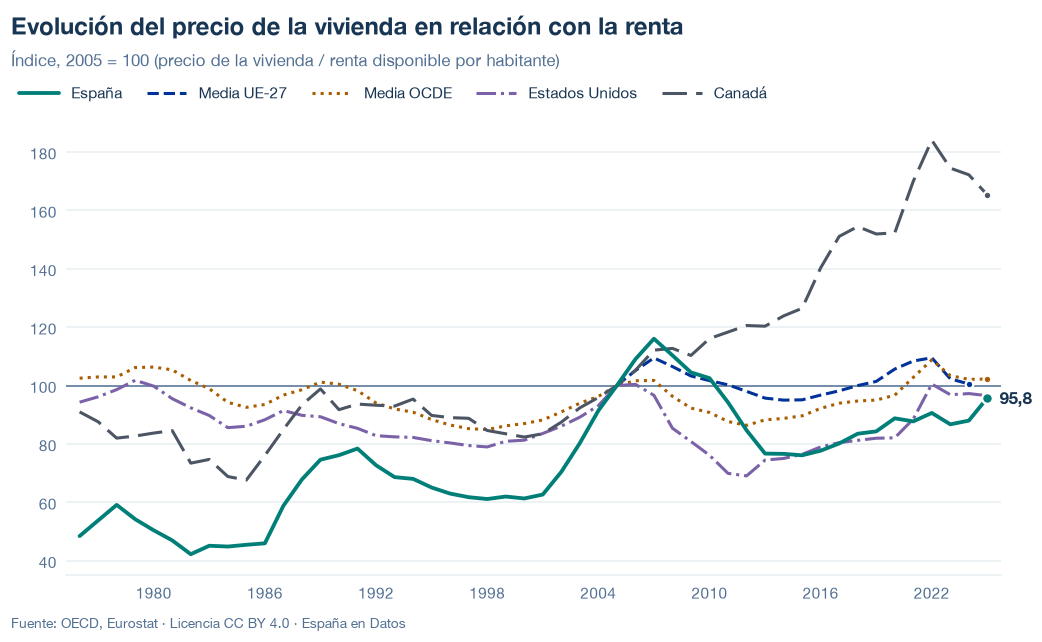

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/indice-precio-vivienda-renta.json y data/indice-precio-vivienda-renta.csv


## 6. Fuentes, notas y licencia

- OCDE, *Analytical house price indicators* (`OECD.ECO.MPD,DSD_AN_HOUSE_PRICES@DF_HOUSE_PRICES`), `HPI_YDH`.
- Eurostat, `tipsho60`.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.